In [1]:
import cogsworth
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import astropy.units as u
import astropy.coordinates as coords

In [2]:
# this all just makes plots look nice
%config InlineBackend.figure_format = 'retina'

plt.rc('font', family='serif')
plt.rcParams['text.usetex'] = False
fs = 24

# update various fontsizes to match
params = {'figure.figsize': (12, 8),
          'legend.fontsize': fs,
          'axes.labelsize': fs,
          'xtick.labelsize': 0.9 * fs,
          'ytick.labelsize': 0.9 * fs,
          'axes.linewidth': 1.1,
          'xtick.major.size': 7,
          'xtick.minor.size': 4,
          'ytick.major.size': 7,
          'ytick.minor.size': 4}
plt.rcParams.update(params)
pd.options.display.max_columns = 999

In [5]:
p = cogsworth.pop.Population(200_000, final_kstar1=[14], sampling_params={"qmin": 0.01},
                             sampling_mask="mass_2 < 2", use_default_BSE_settings=True)
p.sample_initial_binaries()
p.perform_stellar_evolution()

In [6]:
k1, k2 = p.final_bpp["kstar_1"].values, p.final_bpp["kstar_2"].values
bh_star = ((k1 == 14) & (k2 < 10)) | ((k2 == 14) & (k1 < 10))
bound = ~p.disrupted & (p.final_bpp["sep"].values > 0)

bh_pop = p[p.bin_nums[bh_star & bound]]
len(bh_pop)

47

In [9]:
bh_pop.perform_galactic_evolution()

Integrating orbits: 100%|██████████| 47/47 [00:00<00:00, 1244.05it/s]


In [10]:
bh_pop.final_bpp[["mass_1", "mass_2", "kstar_1", "kstar_2", "porb", "ecc"]]

,mass_1,mass_2,kstar_1,kstar_2,porb,ecc
196,24.676604,0.642831,14,0,5.297942e+03,0.185983
384,18.716423,0.908487,14,1,3.655874e+05,0.083244
513,9.892338,0.730337,14,1,8.210359e+03,0.414929
544,7.007015,0.563414,14,0,3.115570e+03,0.229603
749,3.933225,1.609613,14,1,8.177413e+00,0.578381
2111,12.757728,1.066743,14,1,1.550933e+04,0.905061
2344,12.755947,0.859036,14,1,3.238341e+04,0.152706
3589,7.196172,0.949147,14,1,5.401976e-01,0.050377
5123,18.566837,0.794649,14,1,8.080700e+02,0.027491
5967,14.509158,0.694722,14,1,1.292716e+04,0.187025


In [11]:
bh_pop.get_observables(filters=["Gaia_G_EDR3"], ignore_extinction=True,
                       assume_mw_galactocentric=True, silence_bounds_warning=True);

In [12]:
G_original = bh_pop.observables["Gaia_G_EDR3_app"].values.copy()
f"{((G_original >= 13) & (G_original <= 21)).sum()} of {len(bh_pop)} binaries have 13 <= G <= 21"

'30 of 47 binaries have 13 <= G <= 21'

In [13]:
# position of the Sun in the (default astropy) galactocentric frame
galcen = coords.Galactocentric()
sun_pos = [-galcen.galcen_distance.to(u.kpc).value, 0, galcen.z_sun.to(u.kpc).value] * u.kpc

# move every binary 10x closer to the Sun (cheating!)
bh_pop.final_pos[:] = sun_pos + (bh_pop.final_pos - sun_pos) / 10

# recompute the photometry now that the distances have changed
bh_pop.get_observables(filters=["Gaia_G_EDR3"], ignore_extinction=True,
                       assume_mw_galactocentric=True, silence_bounds_warning=True);
G_closer = bh_pop.observables["Gaia_G_EDR3_app"].values

In [20]:
astrometry = bh_pop.get_gaia_astrometry(data_release="dr4", seed=42)
astrometry

,ra,dec,parallax,pmra,pmdec,m1,m2,period,Tp,ecc,omega,inc_deg,w,phot_g_mean_mag,f,A_G,a_arcsec,solution_type,ruwe,accel_significance,f2,fit_parallax,fit_parallax_err,fit_period,fit_period_err,fit_ecc,fit_ecc_err,fit_inc_deg,fit_a0,fit_a0_err,n_vis_periods,n_obs,published_dr3,published_dr4_loose
196,299.890851,30.155627,0.460977,6.796077,10.108632,0.642831,24.676604,5.297942e+03,4.856857e+03,0.185983,5.544055,62.160623,5.764748,18.268757,0.0,-3.552714e-15,0.008048,single_star,1.268863,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
513,209.779415,-63.039882,1.418403,-12.270093,-9.726222,0.730337,9.892338,8.210359e+03,7.479527e+03,0.414929,3.901562,82.880172,5.885115,15.610756,0.0,1.776357e-15,0.024826,orbital,5.534210,NaN,-0.017862,1.394796,0.022044,10000.000000,21526.560115,0.426698,0.605198,83.324579,30.723652,66.870927,60.0,146.0,False,False
544,271.801570,-23.684007,1.070749,44.675535,5.722658,0.563414,7.007015,3.115570e+03,2.731085e+03,0.229603,0.853486,127.575710,0.565346,17.960761,0.0,1.776357e-15,0.008774,orbital,1.915615,NaN,0.109078,1.134955,0.102193,2426.270421,487.501614,0.157460,0.050097,135.686592,5.878903,1.714043,33.0,69.0,False,False
2111,267.410159,-27.313083,0.654663,-3.440732,-1.192063,1.066743,12.757728,1.550933e+04,4.797321e+03,0.905061,4.576889,99.989592,4.885437,14.586867,0.0,1.776357e-15,0.019117,single_star,0.996262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
2344,178.271830,-61.582622,1.103124,-29.061284,2.211343,0.859036,12.755947,3.238341e+04,3.091502e+04,0.152706,4.958051,102.520582,3.995542,14.864239,0.0,-1.776357e-15,0.052355,single_star,1.079333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
3589,277.243787,-7.813184,0.610125,0.945582,10.566706,0.949147,7.196172,5.401976e-01,9.458567e-02,0.050377,1.997253,95.689886,5.148613,15.680450,0.0,0.000000e+00,0.000016,single_star,1.002498,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
5123,118.500107,-25.521256,1.715546,32.118190,-65.915493,0.794649,18.566837,8.080700e+02,8.053453e+02,0.027491,0.234066,88.870935,4.048502,14.152328,0.0,3.552714e-15,0.007819,orbital,16.120703,NaN,-0.558873,1.712025,0.011451,807.968505,0.301449,0.036500,0.003227,88.854134,7.523607,0.012254,58.0,192.0,True,True
5967,295.443347,35.209125,0.691253,3.751178,15.559900,0.694722,14.509158,1.292716e+04,9.721658e+03,0.187025,0.489591,71.000962,4.646119,17.351162,0.0,0.000000e+00,0.018453,single_star,1.095322,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
7200,225.264372,-59.087100,0.527096,-2.915388,-3.062321,1.255901,15.070407,9.922993e+03,1.492231e+03,0.316507,3.194178,92.992169,5.822285,14.719415,0.0,0.000000e+00,0.012080,orbital,1.599497,NaN,0.154271,0.542764,0.015860,10000.000000,133660.113842,0.376636,4.220884,87.700914,4.268809,64.109154,46.0,107.0,False,False
11029,298.144415,45.531501,0.648401,11.727412,23.204497,0.668117,5.449875,1.068439e+01,4.095776e+00,0.532385,3.248885,121.962368,3.816380,17.228660,0.0,1.776357e-15,0.000113,single_star,1.007910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False


In [21]:
astrometry["solution_type"].value_counts()

solution_type
single_star    26
orbital         9
accel7          4
accel9          2
Name: count, dtype: int64

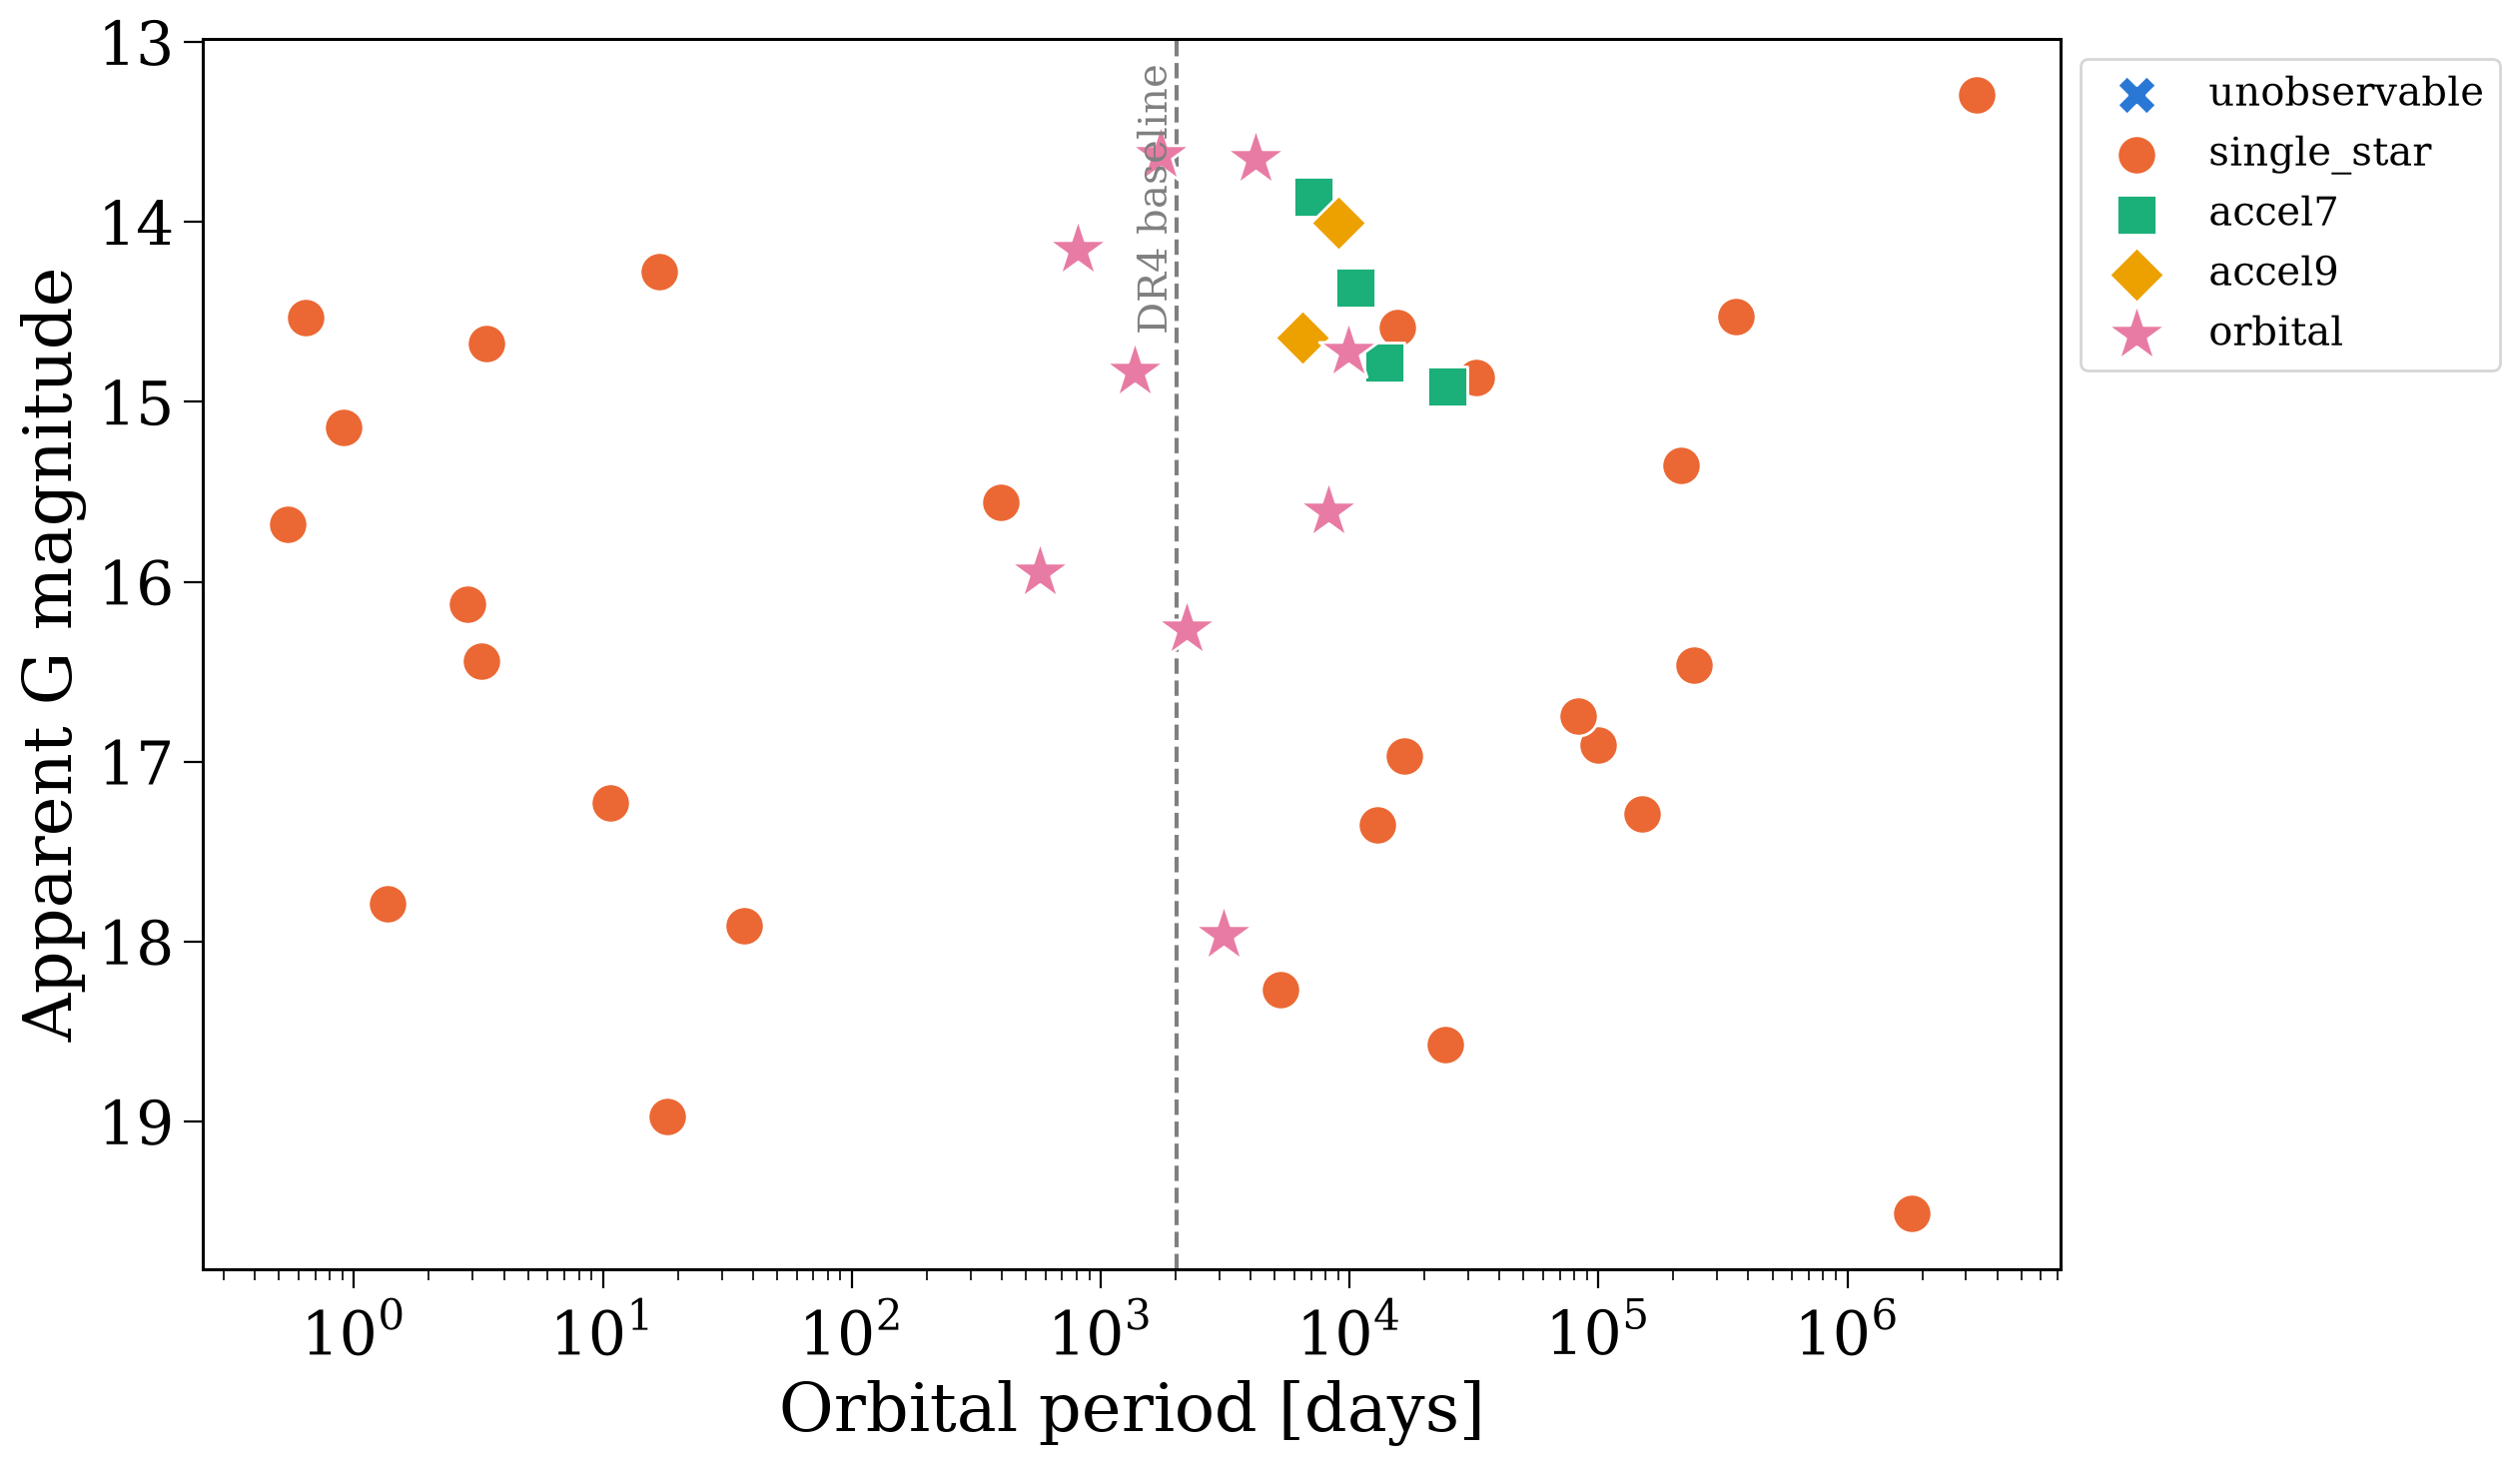

In [24]:
solution_types = ["unobservable", "single_star", "accel7", "accel9", "orbital"]
colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
markers = ["X", "o", "s", "D", "*"]
sizes = [200, 200, 200, 200, 500]

fig, ax = plt.subplots()

for sol, colour, marker, size in zip(solution_types, colours, markers, sizes):
    mask = astrometry["solution_type"] == sol
    ax.scatter(astrometry["period"][mask], astrometry["phot_g_mean_mag"][mask],
               color=colour, marker=marker, s=size, edgecolor="white", label=sol, zorder=2)

# DR4 covers about 66 months of observations
ax.axvline(5.5 * 365.25, color="grey", linestyle="--", zorder=1)
ax.annotate("DR4 baseline", xy=(5.5 * 365.25, 0.98), xycoords=("data", "axes fraction"),
            ha="right", va="top", rotation=90, fontsize=0.6 * fs, color="grey")

ax.set(xscale="log", xlabel="Orbital period [days]", ylabel="Apparent G magnitude")
ax.invert_yaxis()
ax.legend(fontsize=0.6 * fs, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

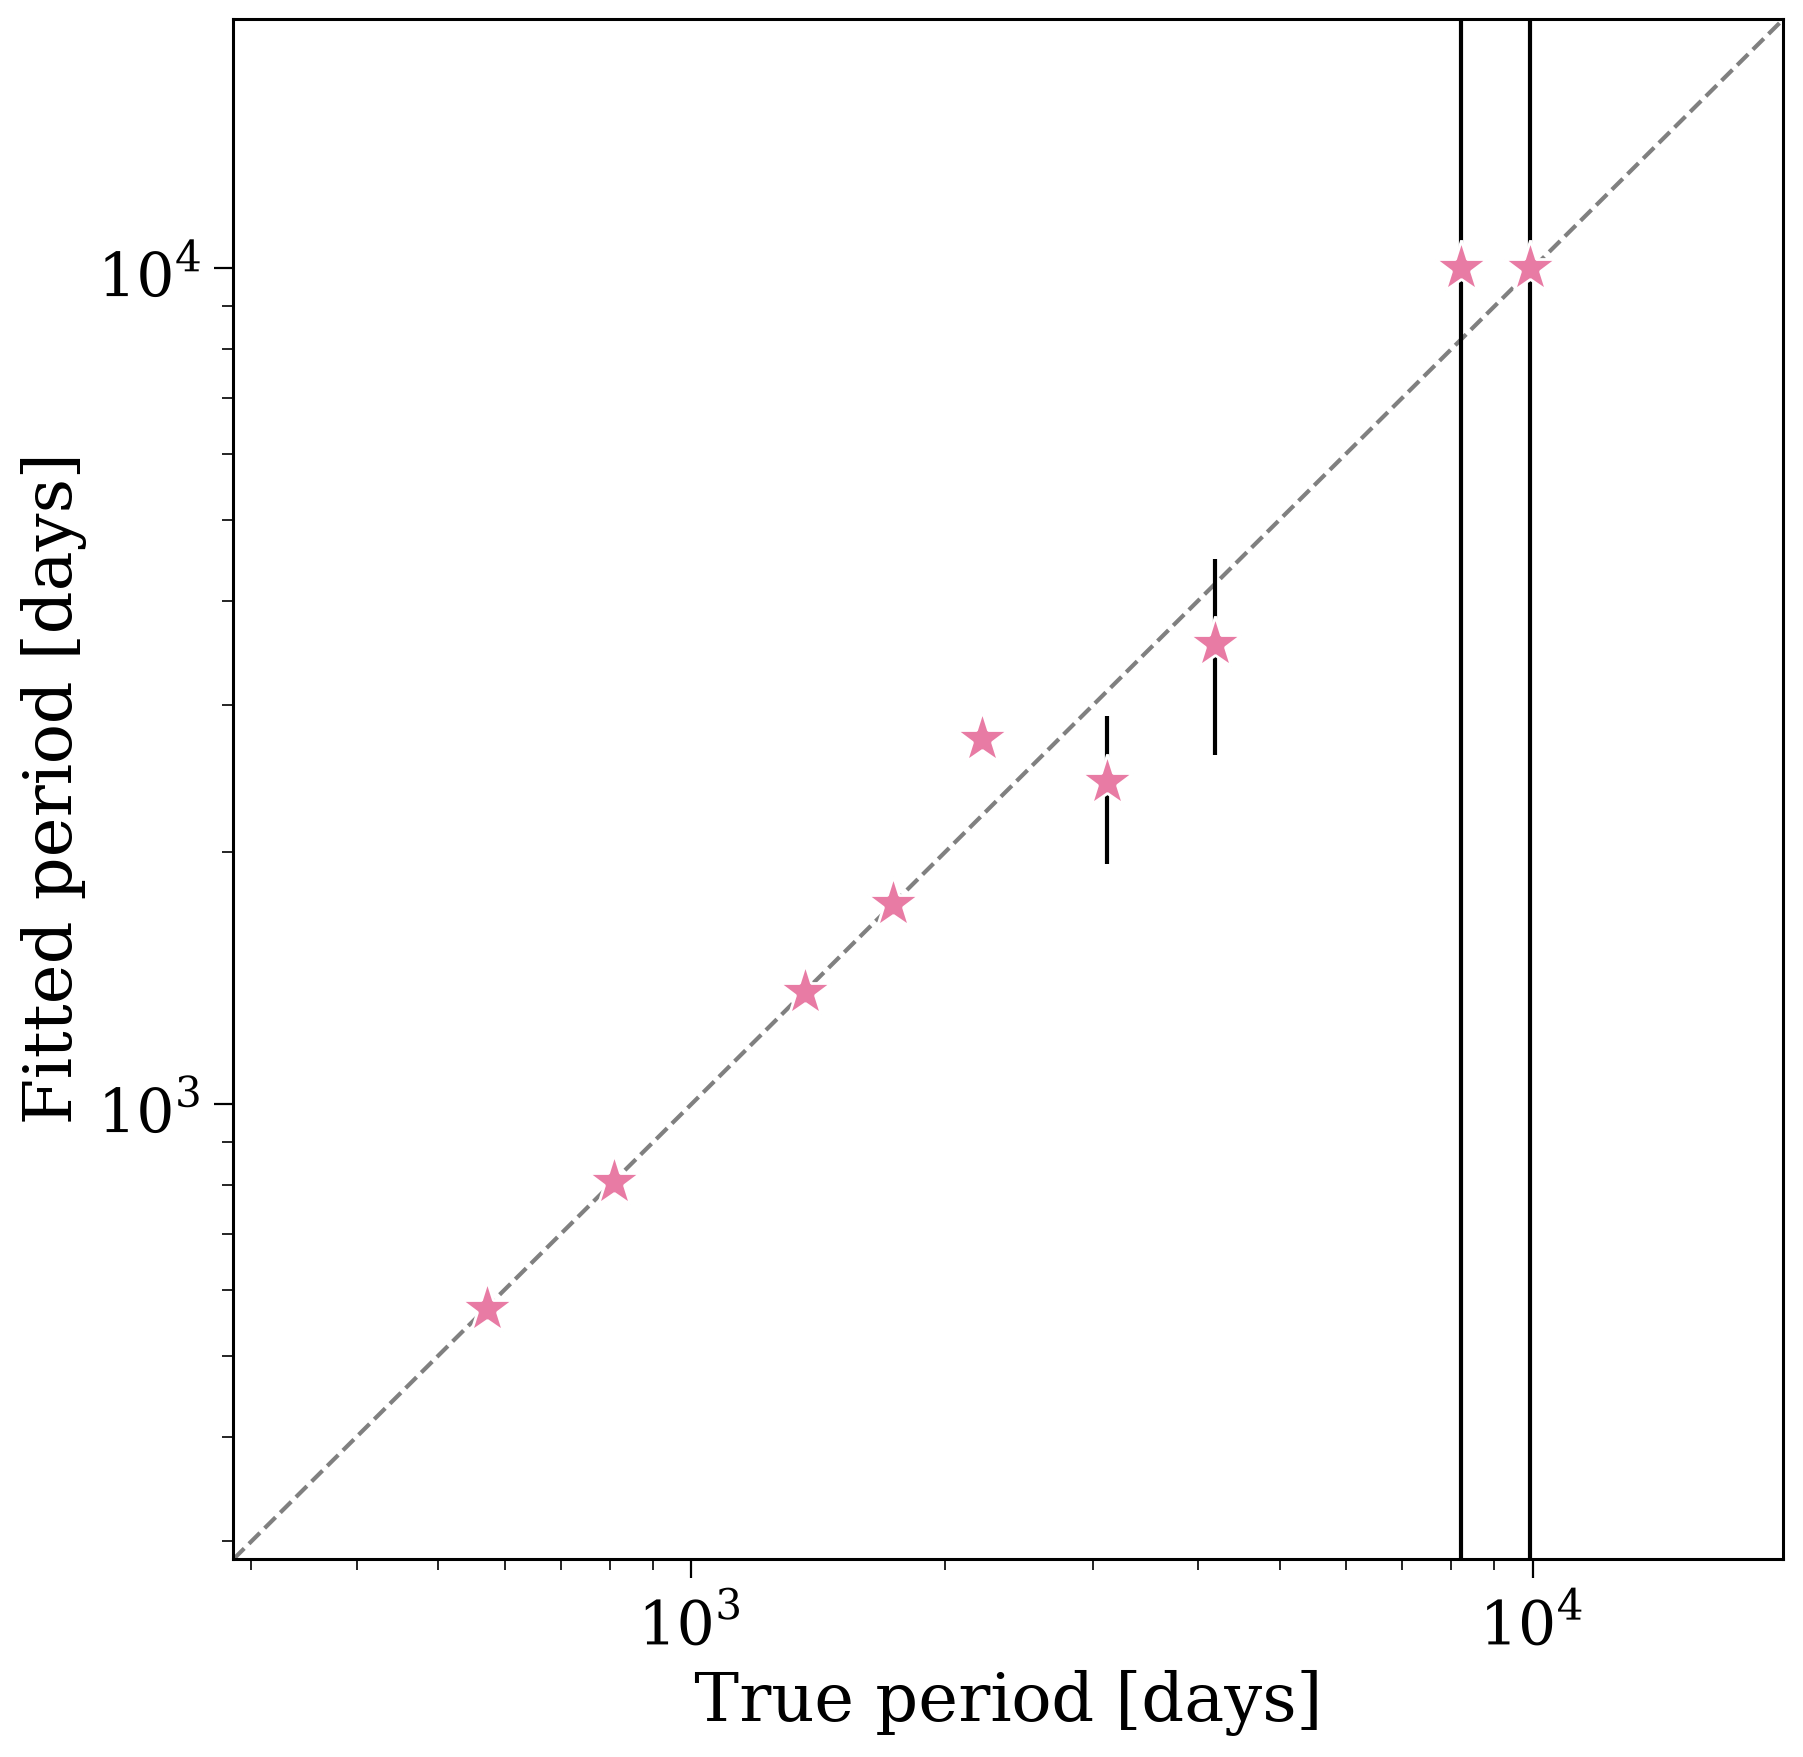

In [26]:
orbital = astrometry["solution_type"] == "orbital"

fig, ax = plt.subplots(figsize=(10, 10))
ax.errorbar(astrometry["period"][orbital], astrometry["fit_period"][orbital],
            yerr=astrometry["fit_period_err"][orbital], fmt="*", color="#e87ba4",
            markersize=20, markeredgecolor="white", ecolor="black")

# add a one-to-one line for reference
lims = [np.min(astrometry["period"][orbital]) / 2, astrometry["period"][orbital].max() * 2]
ax.plot(lims, lims, color="grey", linestyle="--", zorder=0)

ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="True period [days]", ylabel="Fitted period [days]")
plt.show()

In [27]:
astrometry_dr3 = bh_pop.get_gaia_astrometry(data_release="dr3", seed=42)

pd.DataFrame({
    "DR3": astrometry_dr3["solution_type"].value_counts(),
    "DR4": astrometry["solution_type"].value_counts(),
}).reindex(solution_types).fillna(0).astype(int)

,DR3,DR4
solution_type,,
unobservable,0,0
single_star,33,26
accel7,2,4
accel9,1,2
orbital,5,9


In [28]:
f'Published orbits: {astrometry_dr3["published_dr3"].sum()} in DR3, {astrometry["published_dr4_loose"].sum()} in DR4'

'Published orbits: 2 in DR3, 4 in DR4'